In [ ]:
# %pip install scikit_learn

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl (36.7 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import *

In [6]:
import torch
from torch import nn # neural network
from torch.optim import Adam # parameter 최적화 알고리즘인 Adam
from torch.utils.data import TensorDataset, DataLoader # 데이터 다루는 도구

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [ ]:
# %pip install requests

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached charset_normalizer-3.5.2-cp312-cp312-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)
Using cached charset_normalizer-3.5.2-cp312-cp312-win_amd64.whl (207 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
Using cached urllib3-2.8.0-py3-none-any.whl (135 kB)
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
# 데이터 불러오기
import requests
from io import BytesIO
import certifi

path = 'https://bit.ly/advertising_csv'
response = requests.get(path,verify=certifi.where(),timeout=15)
response.raise_for_status()
adv = pd.read_csv(BytesIO(response.content))

# x, y 분할
target = 'Sales'
x = adv.drop(target, axis= 1)
y = adv.loc[:, target]

# 학습 / 검증 데이터 분리
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size= .2, random_state=20)

print(type(x_train), type(x_val)) # 판다스 데이터프레임

# 스케일링
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

print(type(x_train), type(x_val)) # numpy ndarray

<class 'pandas.DataFrame'> <class 'pandas.DataFrame'>
<class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [11]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Check source data
print("SOURCE DATA")
print("x_train:", type(x_train), x_train.shape)
print("y_train:", type(y_train), y_train.shape)
print("x_val:", type(x_val), x_val.shape)
print("y_val:", type(y_val), y_val.shape)

# Recreate tensors
x_train_ts = torch.as_tensor(x_train, dtype=torch.float32)
y_train_ts = torch.as_tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)

x_val_ts = torch.as_tensor(x_val, dtype=torch.float32)
y_val_ts = torch.as_tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1)

# Check tensor dimensions
print("\nTENSORS")
print("x_train_ts:", x_train_ts.shape, x_train_ts.size(0))
print("y_train_ts:", y_train_ts.shape, y_train_ts.size(0))
print("x_val_ts:", x_val_ts.shape, x_val_ts.size(0))
print("y_val_ts:", y_val_ts.shape, y_val_ts.size(0))

# Verify alignment
assert x_train_ts.size(0) == y_train_ts.size(0)
assert x_val_ts.size(0) == y_val_ts.size(0)

# Create datasets
train_ds = TensorDataset(x_train_ts, y_train_ts)
val_ds = TensorDataset(x_val_ts, y_val_ts)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)

print("\nSUCCESS")
print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))

SOURCE DATA
x_train: <class 'numpy.ndarray'> (160, 3)
y_train: <class 'pandas.Series'> (160,)
x_val: <class 'numpy.ndarray'> (40, 3)
y_val: <class 'pandas.Series'> (40,)

TENSORS
x_train_ts: torch.Size([160, 3]) 160
y_train_ts: torch.Size([160, 1]) 160
x_val_ts: torch.Size([40, 3]) 40
y_val_ts: torch.Size([40, 1]) 40

SUCCESS
Training samples: 160
Validation samples: 40


C:\Users\keeus\AppData\Local\Temp\ipykernel_5856\429771204.py:13: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  y_train_ts = torch.as_tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)


In [12]:
# 모델 선언
in_features = x_train_ts.shape[1]
model = nn.Sequential(
    nn.Linear(in_features, 1),
).to(device)

In [13]:
# 손실함수와 옵티마이저 정의
loss_fn = nn.MSELoss()
optimizer = Adam(model.parameters(), lr=0.01)  # 오차 최소화를 위한 모델의 가중치 조정

In [15]:
EPOCHS =100 # 학습 주기
tr_loss_list, val_loss_list = [], []

# 1. 학습 데이터 반복 학습
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    n_batch = 0

    # 2. 에포크마다 배치 단위 학습
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        # 3. 학습
        # 오차 순전파 : 학습 데이터에서 오차 계산
        pred = model(x)             # 모델에 x를 입력해 예측
        loss = loss_fn(pred, y)     # 오차 계산

        # 오차 역전파 : 오차로부터 가중치 업데이트
        optimizer.zero_grad()       # 기울기 초기화
        loss.backward()             # 손실 함수를 기준으로 각 가중치의 기울기를 계산
        optimizer.step()            # 기울기를 기준으로 가중치 조정

        total_loss += loss.item()
        n_batch += 1
    
    # 에포크마다 학습 오차 집계
    tr_loss= total_loss / n_batch

    # 4. 검증
    model.eval()    # 모델평가 / 추론 모드
    with torch.no_grad():
        val_pred = model(x_val_ts)
        val_loss = loss_fn(val_pred, y_val_ts)

    tr_loss_list.append(tr_loss)
    val_loss_list.append(val_loss)
    print(f"Epoch {epoch+1 : 4d} | train loss {tr_loss : 4f} | val loss {val_loss: .4f}")

Epoch    1 | train loss  228.065125 | val loss  238.5053
Epoch    2 | train loss  224.656570 | val loss  235.1197
Epoch    3 | train loss  221.292560 | val loss  231.7583
Epoch    4 | train loss  218.028113 | val loss  228.4111
Epoch    5 | train loss  214.782864 | val loss  225.0922
Epoch    6 | train loss  211.468411 | val loss  221.8348
Epoch    7 | train loss  208.297330 | val loss  218.5991
Epoch    8 | train loss  205.107245 | val loss  215.4072
Epoch    9 | train loss  202.032910 | val loss  212.2300
Epoch   10 | train loss  198.840094 | val loss  209.1284
Epoch   11 | train loss  195.804205 | val loss  206.0512
Epoch   12 | train loss  192.758307 | val loss  203.0185
Epoch   13 | train loss  189.843942 | val loss  199.9899
Epoch   14 | train loss  186.845056 | val loss  197.0182
Epoch   15 | train loss  183.978632 | val loss  194.0616
Epoch   16 | train loss  181.069617 | val loss  191.1557
Epoch   17 | train loss  178.224176 | val loss  188.2859
Epoch   18 | train loss  175.42

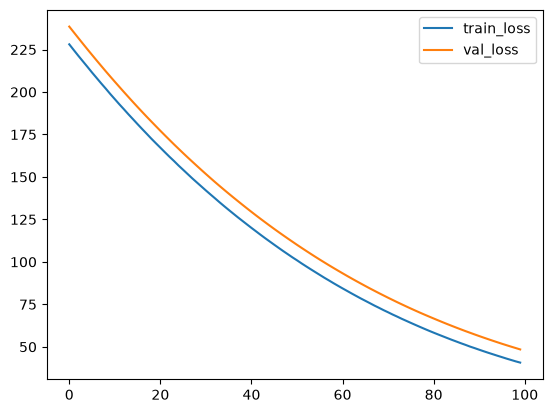

In [16]:
# 학습곡선
plt.plot(tr_loss_list, label= 'train_loss')
plt.plot(val_loss_list, label= 'val_loss')
plt.legend()
plt.show()